# Delivery optimisation with capacity and time windows: presentation and pre-analysis

This study investigates how customers can be assigned to vehicles and deliveries sequenced so that fleet size is minimised first and total distance second, respecting vehicle capacity and time windows. Framed as prescriptive analytics, the final output is an independently verifiable route plan (the ordered sequence of customers per vehicle) comparable against published references. The formulation addresses a classic combinatorial variant of the vehicle routing problem (Dantzig & Ramser, 1959) with time windows (Toth & Vigo, 2014).

Evaluation uses the Solomon benchmark (Solomon, 1987), consisting of synthetic instances with 100 customers, a single depot, a homogeneous fleet, planar Euclidean distance and travel time numerically equal to distance (unit speed). Time windows are hard for the start of service: arriving before opening forces the vehicle to wait, whereas arriving after closing renders the plan infeasible. This represents a benchmark convention rather than real-world practice, where early deliveries are often accepted upon customer availability, freeing slack for the rest of the route. Consequently, that relaxation is analysed separately as a business scenario (Layer B).

Because these instances are synthetic, benchmark runs abstract away operational elements such as road networks, traffic, stochastic travel times, driver costs, heterogeneous fleets, dynamic orders, multiple time windows or penalised lateness. As the dataset contains no real logistics telemetry, the results strictly measure algorithmic behaviour in a controlled setting.

Within the portfolio, the project continues the theme of the Olist delivery study from a prescriptive routing angle. The analysis relies solely on Solomon benchmark data, since the marketplace dataset records no fleet, capacity, time-window or routing information. This notebook documents data provenance, instance inventory, validation contracts, objective conventions and methodological decisions, setting up the exploratory analysis in notebook 02 without invoking any solver.

## 1. Environment setup

In this stage the 56 Solomon instances (from the SINTEF archive) and two reference tables are loaded: SINTEF (2008), which follows a hierarchical vehicles-then-distance convention, and CVRPLIB (s.d.), which publishes routes and costs under truncated distances. File locations are resolved via `paths.data_paths()`, allowing the notebook to run from any project directory. The table counts the records read from each source.

In [1]:
LANG = "en"  # "pt" or "en"

import matplotlib.pyplot as plt
from IPython.display import display

from delivery_routing_vrptw import benchmark, eda, io, paths, viz_eda
from delivery_routing_vrptw.viz import setup_notebook_figures

setup_notebook_figures()

P = paths.data_paths()
instances = io.read_archive(P["sintef_zip"])
sintef = io.read_references(P["sintef_bks"])
cvrplib = io.read_cvrplib_references(P["cvrplib_bks"])

display(eda.localize_columns(eda.loaded_counts(instances, sintef, cvrplib, LANG), LANG))

,Item,Count
0,Instances loaded (SINTEF),56
1,"SINTEF references (vehicles, distance)",56
2,"CVRPLIB references (routes, cost)",56


### Insight

The loaders read 56 instances from the SINTEF archive, 56 SINTEF references (vehicles and distance) and 56 CVRPLIB solutions (routes and cost). All three sources cover the exact same 56 problems, preventing case omissions in subsequent comparisons. As a limitation, the SINTEF reference table was transcribed manually from a PDF snapshot; although row counts match, individual entries lack automated hash verification. Next, the integrity of the archived source packages is checked.

## 2. Data provenance

To verify whether the files versioned in the repository match the originally downloaded archives, the SHA-256 digest of each package was compared against the value recorded in its respective `MANIFEST.md`. The table lists the calculated and recorded digest prefixes alongside the full-match status.

In [2]:
display(eda.localize_columns(eda.provenance_table(P), LANG))

,File,Computed SHA-256,MANIFEST SHA-256,Matches
0,solomon-100.zip,8a0a72cbe6b7f8f9…,8a0a72cbe6b7f8f9…,True
1,Solomon.7z,55ba67b56a478554…,55ba67b56a478554…,True
2,Solomon-solutions.7z,88a5d385c0faf63e…,88a5d385c0faf63e…,True


### Insight

All three versioned archives (`solomon-100.zip`, `Solomon.7z` and `Solomon-solutions.7z`) produce SHA-256 digests identical to their recorded `MANIFEST.md` values (3 of 3 with `Matches = True`), confirming that the working inputs match the files downloaded on 2026-11-17. While the hashes prove that the archives remained unaltered after collection, they verify neither the accuracy of the upstream source nor the derived and transcribed CSV files (SINTEF and CVRPLIB tables). With archive integrity confirmed, the structural inventory proceeds from the versioned packages.

## 3. Inventory by family

Solomon instances are grouped into six families defined by spatial distribution and horizon length. Letters denote customer geometry (C for clustered, R for random and RC for mixed), while digits separate operational series (1 for short horizons and shorter routes, and 2 for long horizons and larger vehicle capacities). The summary table lists instance and customer counts, fleet limits (K), vehicle capacities (Q), horizons, median service times and mean total demand per family.

In [3]:
display(eda.localize_columns(eda.family_summary(instances), LANG))

,Family,No. of instances,No. of customers,Fleet limit (K),Capacity (Q),Horizon,Service time,Mean total demand
0,C1,9,100,25,200,1236,90.0,1810.0
1,C2,8,100,25,700,3390,90.0,1810.0
2,R1,12,100,25,200,230,10.0,1458.0
3,R2,11,100,25,1000,1000,10.0,1458.0
4,RC1,8,100,25,200,240,10.0,1724.0
5,RC2,8,100,25,1000,960,10.0,1724.0


### Insight

The 56 instances divide into six families: 9 in C1, 8 in C2, 12 in R1, 11 in R2, 8 in RC1 and 8 in RC2, each containing 100 customers with a fleet upper bound K = 25. Vehicle capacity equals 200 in series 1 (C1, R1, RC1), 700 in C2 and 1000 in R2 and RC2; horizons span from 230 (R1) to 3390 (C2); service duration is 90 units in the C families and 10 in R and RC. Within each spatial class, mean total demand stays identical across series (1810 in C, 1458 in R and 1724 in RC), so moving from series 1 to series 2 alters capacity and time horizon while preserving total load. Because family means mask internal dispersion, instance-level variability is inspected in notebook 02; prior to that, compliance with the data contract is tested.

## 4. Data contract

Before exploratory analysis, a structural integrity contract was defined and checked per rule and per instance, as specified below.

| Field | Unit | Rule |
|---|---|---|
| `VEHICLE NUMBER` (K) | vehicles | upper bound on the fleet |
| `CAPACITY` (Q) | demand units | same capacity for every vehicle |
| Node 0 |, | depot: demand 0, service time 0; `DUE DATE` = end of the horizon |
| `XCOORD`, `YCOORD` | distance units | integers; Euclidean plane |
| `DEMAND` | demand units | integer ≥ 0; ≤ capacity |
| `READY TIME` / `DUE DATE` | time units (= distance) | `READY` ≤ `DUE` ≤ horizon; hard window for the start of service |
| `SERVICE TIME` | time units | constant per family |
| IDs |, | 0..100, contiguous |

The summary below reports how many of the 56 instances satisfy each rule.

In [4]:
check = eda.contract_check(instances)
display(eda.localize_columns(eda.contract_summary(check, LANG), LANG))

,Rule,Instances passing,No. of instances
0,Contiguous IDs,56,56
1,Depot without demand/service,56,56
2,Demand ≤ capacity,56,56
3,Ready ≤ due,56,56
4,Windows within horizon,56,56
5,All rules,56,56


### Insight

All 56 instances satisfy the five tested rules (56 of 56 on every row, including `All rules`), requiring zero exclusions. Because the instance parser already rejects malformed files on load, this table documents post-load compliance while contiguous IDs are inferred from uniform array lengths, rather than serving as an independent parser audit. With the full dataset validated, attention turns to objective conventions.

## 5. Objective conventions: SINTEF vs CVRPLIB

Reference solutions from SINTEF and CVRPLIB follow distinct conventions. SINTEF adopts a hierarchical objective (minimising fleet size first and total distance second) using double-precision arithmetic rounded to two decimal places (Bräysy & Gendreau, 2005a; SINTEF, 2008). CVRPLIB minimises total distance alone with up to K routes, truncating Euclidean arc distances to one decimal place (CVRPLIB, s.d.).

To measure the practical consequences of this discrepancy, published CVRPLIB routes were re-evaluated by an independent checker under both conventions and compared against SINTEF records. Checks covered feasibility (capacity, time windows and depot return) under truncated and exact distances, reproduction of published CVRPLIB costs (tolerance 0.05), fleet differences and, where fleets match, reproduction of SINTEF distances (tolerance 0.01). The table summarises these counts, while the scatter plot displays the vehicle difference SINTEF − CVRPLIB on the horizontal axis (negative values mean smaller SINTEF fleets) and the percentage distance excess of SINTEF over exact-distance CVRPLIB routes on the vertical axis.

,Indicator,Value
0,Instances compared,56
1,CVRPLIB solutions feasible under truncated dis...,56
2,Published cost reproduced (±0.05) under trunca...,56
3,CVRPLIB solutions feasible under exact distance,48
4,Instances infeasible under exact distance,"8: R102, R105, R107, R108, R112, R211, RC101, ..."
5,Instances where SINTEF uses fewer vehicles,37
6,Instances where SINTEF uses more vehicles,0
7,Instances with equal fleet under both conventions,19
8,Equal fleet with SINTEF distance reproduced (±...,19
9,Largest vehicle difference (CVRPLIB − SINTEF),5


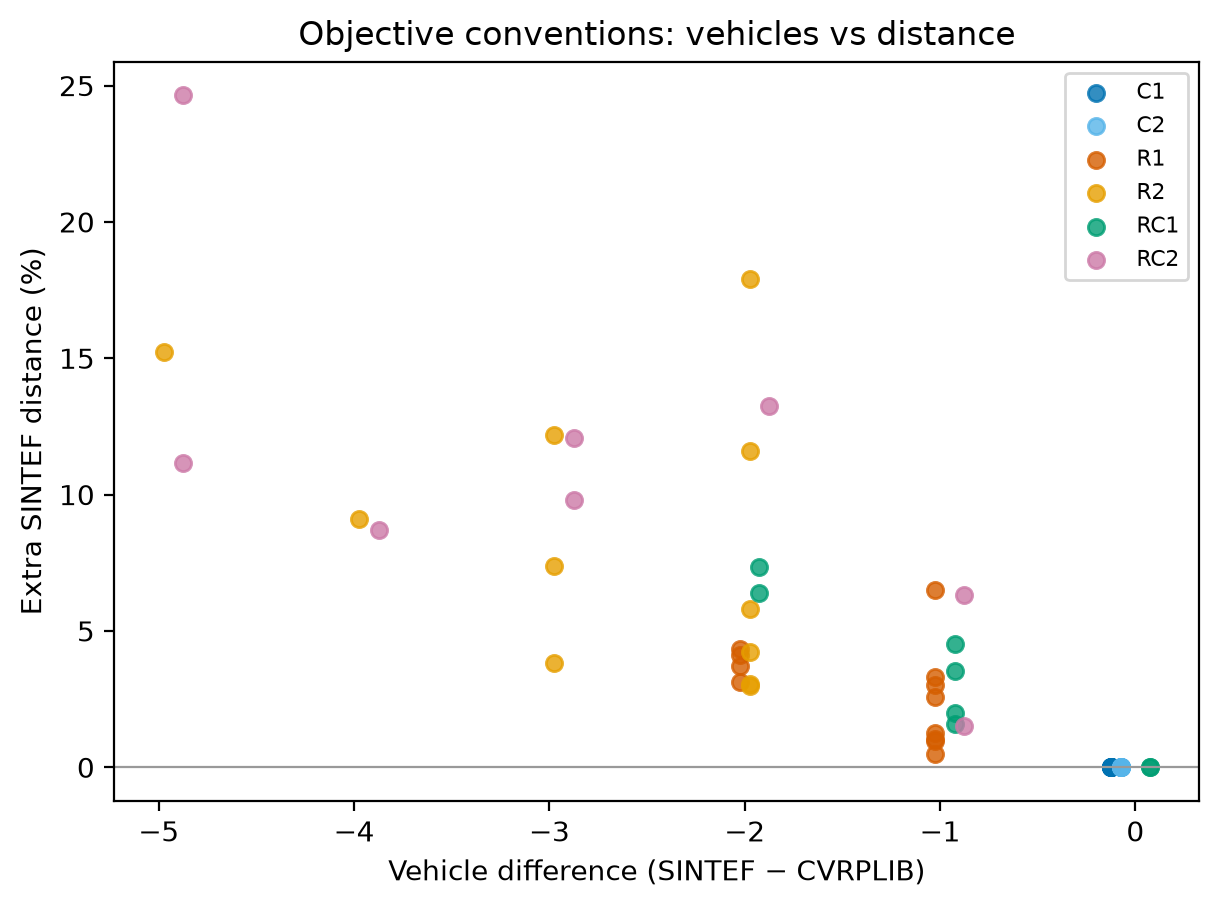

In [5]:
conv = eda.convention_comparison(instances, sintef, cvrplib)
display(eda.localize_columns(eda.convention_summary(conv, LANG), LANG))

viz_eda.plot_convention_tradeoff(conv, LANG)
plt.show()

### Insight

All 56 CVRPLIB solutions are feasible under truncated distances and match published costs within 0.05, validating the independent checker under CVRPLIB rules. When recalculated in double precision, however, 48 remain feasible and 8 (R102, R105, R107, R108, R112, R211, RC101 and RC105) violate time windows due to accumulated rounding differences. Across conventions, SINTEF uses fewer vehicles on 37 instances (up to 5 fewer) and the same fleet on the remaining 19 (all C instances plus two in RC1, clustered at x = 0 and y ≈ 0, where SINTEF distances are reproduced within ±0.01 in all 19 cases). On the 37 instances with smaller fleets, points lie in the negative-x quadrant and SINTEF distances exceed exact CVRPLIB routes by 0.5% to 24.6%.

Two limitations qualify these numbers: the exact distances reported for the 8 infeasible CVRPLIB solutions correspond to invalid schedules with window violations, and the plotted pairing between fewer vehicles and longer routes reflects empirical co-occurrence rather than direct causality. All primary benchmark comparisons in this project therefore follow SINTEF's hierarchical double-precision convention, keeping CVRPLIB strictly as a secondary reference in separate tables.

## 6. Implications and decisions

The project separates two independent analysis layers. Layer A (benchmark) solves Solomon's hard VRPTW under a lexicographic objective (fleet then distance) against SINTEF references, requiring zero window violations and zero unserved customers. Layer B (business scenarios) explores operational variations such as flexible windows, customer priorities and execution perturbations under a declared weighted cost without computing gaps against the benchmark.

All primary comparisons adhere strictly to SINTEF's hierarchical double-precision convention, leaving CVRPLIB for separate secondary tables. Because SINTEF values come from heuristic best known solutions rather than proven optima, optimality claims are avoided and distance gaps are computed only when the fleet matches the reference.

To prevent data leakage, a pre-registered stratified split separates development and evaluation instances (Nosek et al., 2018), restricting configuration tuning to the development subset while reserving the remainder for final evaluation. A deviation from the strict pre-analysis rule is recorded as of 2026-11-18: whereas the initial plan deferred reading evaluation SINTEF entries until the final tournament, notebooks 01 and 02 load all 56 published reference values descriptively to inspect conventions and fleet bounds, without using them to select configurations, budgets or parameters. Next, notebook 02 inspects geography, capacities and time windows without running any solver.

The table derived from `data/reference/split.csv` shows the assignment of instances per family across development and evaluation sets.

In [6]:
split = benchmark.read_split(P["split"])
display(eda.localize_columns(eda.split_summary(split), LANG))

,Family,Development,Evaluation,Total
0,C1,2,7,9
1,C2,2,6,8
2,R1,3,9,12
3,R2,3,8,11
4,RC1,2,6,8
5,RC2,2,6,8
6,Total,14,42,56


### Insight

Stratified sampling allocated 14 instances to development and 42 to evaluation across C1 (2/7), C2 (2/6), R1 (3/9), R2 (3/8), RC1 (2/6) and RC2 (2/6). Given the small size of 2 or 3 development instances per family, observations from this subset act solely as configuration hints. As a scope note, notebook 02 reads inputs for all 56 instances and descriptive SINTEF vehicle bounds including evaluation cases, keeping those published values outside hyperparameter tuning. Notebook 02 proceeds to examine instance geometry and temporal slack without executing optimisation algorithms.

## References

- Bräysy, O., & Gendreau, M. (2005a). Vehicle routing problem with time windows, Part I: Route construction and local search algorithms. *Transportation Science, 39*(1), 104–118.
- CVRPLIB. (s.d.). *VRPTW instances — Solomon set*. PUC-Rio. https://galgos.inf.puc-rio.br/cvrplib/
- Dantzig, G. B., & Ramser, J. H. (1959). The truck dispatching problem. *Management Science, 6*(1), 80–91.
- Nosek, B. A., Ebersole, C. R., DeHaven, A. C., & Mellor, D. T. (2018). The preregistration revolution. *Proceedings of the National Academy of Sciences, 115*(11), 2600–2606.
- SINTEF. (2008). *VRPTW — 100 customers: Solomon benchmark, best known solutions*. SINTEF TOP. https://www.sintef.no/projectweb/top/vrptw/100-customers/
- Solomon, M. M. (1987). Algorithms for the vehicle routing and scheduling problems with time window constraints. *Operations Research, 35*(2), 254–265.
- Toth, P., & Vigo, D. (Eds.). (2014). *Vehicle routing: Problems, methods, and applications* (2nd ed.). SIAM.